<a href="https://colab.research.google.com/github/sucharitacs24/bis-lab/blob/main/Gene%20Expression%20-%20Gene%20Expression%20Programming%3A%20A%20New%20Adaptive%20Algorithm%20for%20Solving%20Problems." target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


GENE EXPRESSION PROGRAMMING RESULTS
-----------------------------------
Best Chromosome: ++1/*/1xxx1x2
Decoded Expression: ((((x / 1) / 1) + (x * x)) + 1)
Best Fitness: 0.0


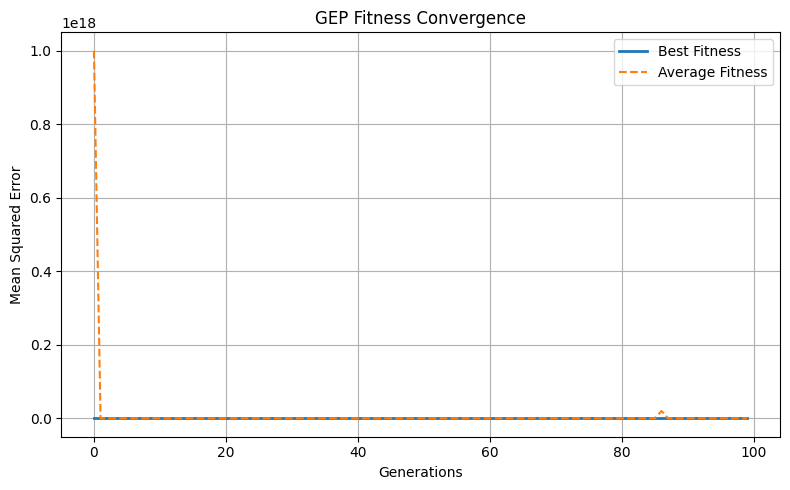

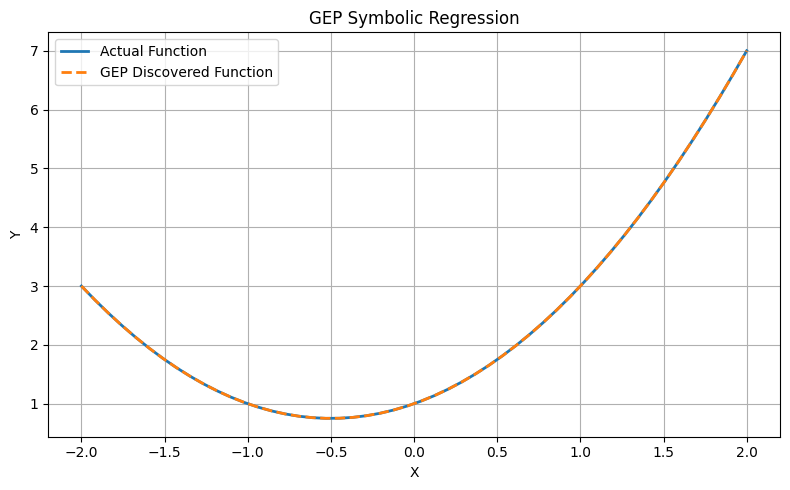

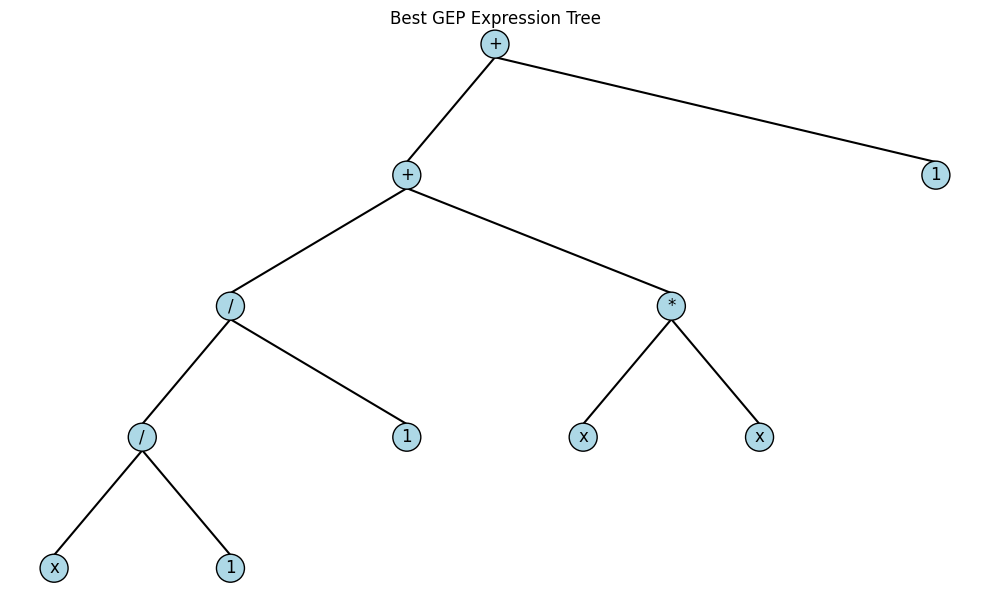

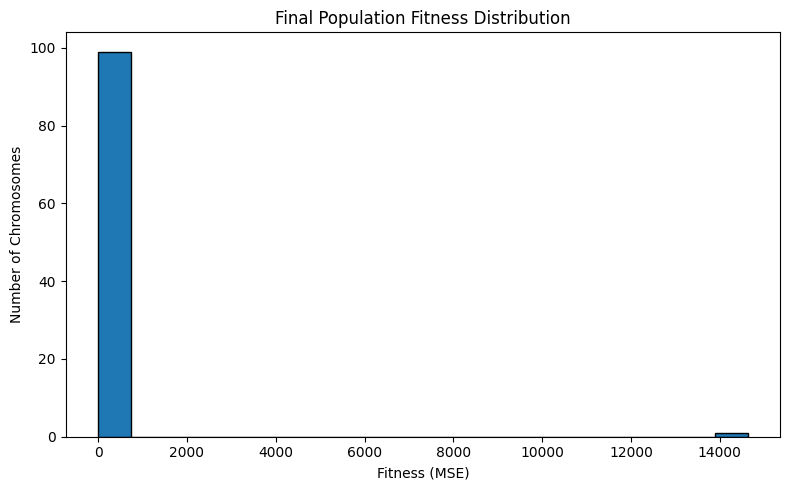

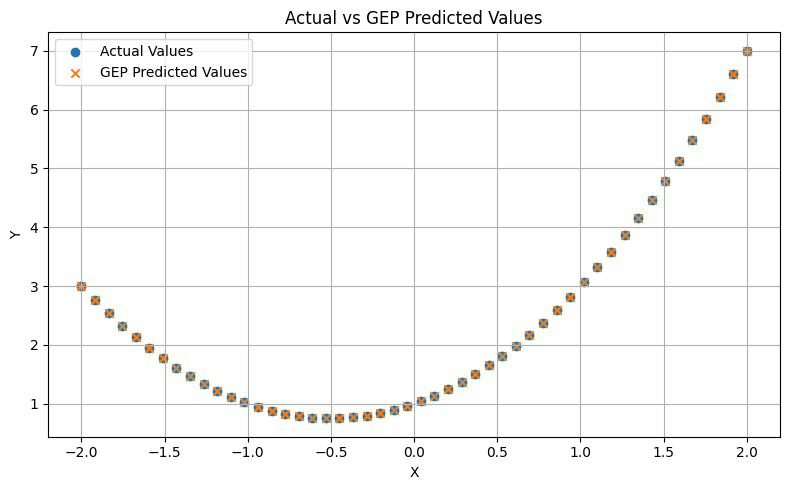

In [1]:

import numpy as np
import random
import matplotlib.pyplot as plt

# ---------------- PARAMETERS ----------------

POP_SIZE = 100
GENERATIONS = 100

HEAD = 6
MAX_ARITY = 2
TAIL = HEAD * (MAX_ARITY - 1) + 1
CHROM_LENGTH = HEAD + TAIL

MUTATION_RATE = 0.03
CROSSOVER_RATE = 0.7
ELITE_SIZE = 2

FUNCTIONS = ['+', '-', '*', '/']
TERMINALS = ['x', '1', '2']

HEAD_SYMBOLS = FUNCTIONS + TERMINALS

random.seed(42)
np.random.seed(42)

# ---------------- PROBLEM DEFINITION ----------------

X = np.linspace(-2, 2, 50)
Y = X**2 + X + 1

# ---------------- CHROMOSOME INITIALIZATION ----------------

def create_chromosome():

    head = [
        random.choice(HEAD_SYMBOLS)
        for _ in range(HEAD)
    ]

    tail = [
        random.choice(TERMINALS)
        for _ in range(TAIL)
    ]

    return head + tail


def initialize_population():

    return [
        create_chromosome()
        for _ in range(POP_SIZE)
    ]

# ---------------- GENE EXPRESSION ----------------

def arity(symbol):

    if symbol in FUNCTIONS:
        return 2

    return 0


def decode(chromosome):

    def make_node(symbol):
        return {
            'symbol': symbol,
            'children': []
        }

    root = make_node(chromosome[0])

    queue = [root]
    index = 1

    while queue and index < len(chromosome):

        parent = queue.pop(0)

        for _ in range(arity(parent['symbol'])):

            if index >= len(chromosome):
                break

            child = make_node(chromosome[index])

            parent['children'].append(child)

            if arity(child['symbol']) > 0:
                queue.append(child)

            index += 1

    return root

# ---------------- EXPRESSION EVALUATION ----------------

def evaluate_tree(node, x):

    symbol = node['symbol']

    if symbol == 'x':
        return x

    if symbol == '1':
        return np.ones_like(x)

    if symbol == '2':
        return np.ones_like(x) * 2

    left = evaluate_tree(node['children'][0], x)
    right = evaluate_tree(node['children'][1], x)

    if symbol == '+':
        return left + right

    if symbol == '-':
        return left - right

    if symbol == '*':
        return left * right

    if symbol == '/':
        return left / np.where(
            np.abs(right) < 1e-10,
            1e-10,
            right
        )

    return np.zeros_like(x)


def predict(chromosome, x):

    tree = decode(chromosome)

    try:
        result = evaluate_tree(tree, x)

        return np.nan_to_num(
            result,
            nan=1e10,
            posinf=1e10,
            neginf=-1e10
        )

    except (ArithmeticError, ValueError, IndexError):
        return np.ones_like(x) * 1e10


# ---------------- FITNESS EVALUATION ----------------

def fitness(chromosome):

    prediction = predict(chromosome, X)

    if np.any(np.abs(prediction) > 1e10):
        return 1e10

    error = np.mean((Y - prediction) ** 2)

    if not np.isfinite(error):
        return 1e10

    return error


# ---------------- EXPRESSION STRING ----------------

def expression(node):

    symbol = node['symbol']

    if not node['children']:
        return symbol

    left = expression(node['children'][0])
    right = expression(node['children'][1])

    return f"({left} {symbol} {right})"


# ---------------- SELECTION ----------------

def selection(population, scores):

    candidates = random.sample(
        range(len(population)), 3
    )

    winner = min(
        candidates,
        key=lambda i: scores[i]
    )

    return population[winner].copy()


# ---------------- MUTATION ----------------

def mutation(chromosome):

    mutated = chromosome.copy()

    for i in range(CHROM_LENGTH):

        if random.random() < MUTATION_RATE:

            if i < HEAD:
                mutated[i] = random.choice(HEAD_SYMBOLS)
            else:
                mutated[i] = random.choice(TERMINALS)

    return mutated


# ---------------- ONE-POINT CROSSOVER ----------------

def crossover(parent1, parent2):

    if random.random() < CROSSOVER_RATE:

        point = random.randint(1, CHROM_LENGTH - 1)

        child1 = (
            parent1[:point] + parent2[point:]
        )

        child2 = (
            parent2[:point] + parent1[point:]
        )

        return child1, child2

    return parent1.copy(), parent2.copy()


# ---------------- MAIN GEP ALGORITHM ----------------

population = initialize_population()

best_history = []
average_history = []

best_chromosome = None
best_fitness = float('inf')

for generation in range(GENERATIONS):

    scores = [
        fitness(chromosome)
        for chromosome in population
    ]

    # Sort population
    ranked = sorted(
        zip(scores, population),
        key=lambda item: item[0]
    )

    # Update best solution
    if ranked[0][0] < best_fitness:

        best_fitness = ranked[0][0]
        best_chromosome = ranked[0][1].copy()

    best_history.append(best_fitness)
    average_history.append(np.mean(scores))

    # Elitism
    new_population = [
        chromosome.copy()
        for score, chromosome in ranked[:ELITE_SIZE]
    ]

    # Generate offspring
    while len(new_population) < POP_SIZE:

        parent1 = selection(population, scores)
        parent2 = selection(population, scores)

        child1, child2 = crossover(parent1, parent2)

        child1 = mutation(child1)
        child2 = mutation(child2)

        new_population.append(child1)

        if len(new_population) < POP_SIZE:
            new_population.append(child2)

    population = new_population

# ---------------- FINAL RESULTS ----------------

best_tree = decode(best_chromosome)

print("\nGENE EXPRESSION PROGRAMMING RESULTS")
print("-----------------------------------")

print("Best Chromosome:", ''.join(best_chromosome))
print("Decoded Expression:", expression(best_tree))
print("Best Fitness:", best_fitness)

# ---------------- GRAPH 1: CONVERGENCE ----------------

plt.figure(figsize=(8, 5))

plt.plot(
    best_history,
    label="Best Fitness",
    linewidth=2
)

plt.plot(
    average_history,
    label="Average Fitness",
    linestyle="--"
)

plt.xlabel("Generations")
plt.ylabel("Mean Squared Error")
plt.title("GEP Fitness Convergence")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------- GRAPH 2: PREDICTION ----------------

predicted = predict(best_chromosome, X)

plt.figure(figsize=(8, 5))

plt.plot(
    X, Y,
    label="Actual Function",
    linewidth=2
)

plt.plot(
    X, predicted,
    '--',
    label="GEP Discovered Function",
    linewidth=2
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("GEP Symbolic Regression")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------- GRAPH 3: EXPRESSION TREE ----------------

def leaf_count(node):

    if not node['children']:
        return 1

    return sum(
        leaf_count(child)
        for child in node['children']
    )


def draw_tree(ax, node, x, y, width, level=0):

    children = node['children']

    ax.text(
        x, y,
        node['symbol'],
        ha='center',
        va='center',
        fontsize=12,
        bbox=dict(
            boxstyle='circle',
            facecolor='lightblue',
            edgecolor='black'
        )
    )

    if not children:
        return

    total = leaf_count(node)
    left_edge = x - width / 2

    for child in children:

        child_width = width * leaf_count(child) / total

        child_x = left_edge + child_width / 2
        child_y = y - 1

        ax.plot(
            [x, child_x],
            [y - 0.1, child_y + 0.1],
            'k-'
        )

        draw_tree(
            ax,
            child,
            child_x,
            child_y,
            child_width,
            level + 1
        )

        left_edge += child_width


fig, ax = plt.subplots(figsize=(10, 6))

draw_tree(
    ax,
    best_tree,
    0,
    0,
    8
)

ax.set_title("Best GEP Expression Tree")
ax.axis('off')

plt.tight_layout()
plt.show()

# ---------------- GRAPH 4: FITNESS DISTRIBUTION ----------------

final_scores = [
    fitness(chromosome)
    for chromosome in population
]

plt.figure(figsize=(8, 5))

plt.hist(
    final_scores,
    bins=20,
    edgecolor='black'
)

plt.xlabel("Fitness (MSE)")
plt.ylabel("Number of Chromosomes")
plt.title("Final Population Fitness Distribution")

plt.tight_layout()
plt.show()

# ---------------- GRAPH 5: FINAL RESULTS ----------------

plt.figure(figsize=(8, 5))

plt.scatter(
    X, Y,
    label="Actual Values"
)

plt.scatter(
    X, predicted,
    marker='x',
    label="GEP Predicted Values"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Actual vs GEP Predicted Values")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
